In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

#setar numero maximo de colunas a serem exibidas para infinito
pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'PRIO3.SA'

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base.tail(10)

[PRIO3.SA] Cache existente cobre de 2020-01-02 a 2025-06-12.
[PRIO3.SA] Cache cobre período solicitado (2022-12-25 a 2025-06-12).
[PRIO3.SA] Retornando 614 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20211225_20250613.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-12.
[^BVSP] Cache cobre período solicitado (2022-12-25 a 2025-06-12).
[^BVSP] Retornando 614 linhas para o período solicitado.


,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,,,
2025-05-30,39.980000,40.230000,38.950001,38.950001,22845000,-0.026250,0.013841,54.786269,0.821041,0.810457,0.010584,1.279999,1.213863,0.031165,0.032863,14.75,0.26,5.7087,138546.000000,138637.00000,136726.0000,137027.00000,15141600
2025-06-02,40.500000,40.599998,39.520000,39.740002,10583600,0.020282,0.015411,58.622523,0.819815,0.812328,0.007487,1.649998,1.245015,0.031329,0.041520,14.75,0.26,5.6937,137026.000000,138471.00000,136483.0000,136787.00000,9100100
2025-06-03,39.200001,41.400002,39.200001,40.950001,11809900,0.030448,0.017939,63.702440,0.906036,0.831070,0.074966,2.200001,1.313228,0.032069,0.053724,14.75,0.26,5.6694,136787.000000,137672.00000,136175.0000,137546.00000,9696700
2025-06-04,41.160000,42.150002,40.610001,40.900002,12365600,-0.001221,0.017972,63.356305,0.959275,0.856711,0.102564,1.540001,1.329427,0.032504,0.037653,14.75,0.26,5.6332,137547.000000,138797.00000,136695.0000,137002.00000,10199100
2025-06-05,41.320000,41.490002,40.770000,41.049999,6252600,0.003667,0.016172,63.988479,1.002020,0.885773,0.116247,0.720001,1.285896,0.031325,0.017540,14.75,0.26,5.5969,137003.000000,137451.00000,136031.0000,136236.00000,9484500
2025-06-06,41.240002,42.599998,41.220001,42.509998,10041300,0.035566,0.018286,69.503425,1.140557,0.936730,0.203828,1.549999,1.304761,0.030693,0.036462,14.75,0.26,5.5947,136236.000000,136890.00000,135601.0000,136102.00000,9119300
2025-06-09,42.619999,42.740002,41.660000,42.150002,6642100,-0.008469,0.019136,66.787453,1.207383,0.990860,0.216523,1.080002,1.288706,0.030574,0.025623,14.75,0.26,5.5760,136102.000000,136106.00000,134119.0000,135699.00000,7763800
2025-06-10,42.619999,43.200001,42.240002,42.570000,8206900,0.009964,0.019143,68.341768,1.279484,1.048585,0.230899,1.049999,1.271656,0.029872,0.024665,14.75,0.26,5.5557,135716.000000,137369.00000,135716.0000,136436.00000,8186500
2025-06-11,43.099998,43.849998,42.669998,43.310001,11168400,0.017383,0.018741,70.923708,1.380423,1.114953,0.265471,1.279999,1.272252,0.029375,0.029554,14.75,0.26,5.5390,136443.000000,137531.00000,135628.0000,137128.00000,8767100


## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-05-30,1.213863,0.031165,1.279999,0.032863
2025-06-02,1.245015,0.031329,1.649998,0.041520
2025-06-03,1.313228,0.032069,2.200001,0.053724
2025-06-04,1.329427,0.032504,1.540001,0.037653
2025-06-05,1.285896,0.031325,0.720001,0.017540
2025-06-06,1.304761,0.030693,1.549999,0.036462
2025-06-09,1.288706,0.030574,1.080002,0.025623
2025-06-10,1.271656,0.029872,1.049999,0.024665
2025-06-11,1.272252,0.029375,1.279999,0.029554


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.86%
Valorização sugerida: 4.29%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [9]:
valorizacao = 0.05
DIAS_FUTURO = 5  # dias futuros para buscar a valorização

In [10]:
df = pp.calcular_target(df_base, x_pct=valorizacao, dias_futuro=DIAS_FUTURO)

In [11]:
df['Target'].value_counts(normalize=True)

Target
0.0    0.796388
1.0    0.203612
Name: proportion, dtype: float64

In [12]:
# Preparar X e y para treino
DIAS_JANELA_X = 15  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True)    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

Colunas removidas por NaN: ['close_vs_mm20', 'mm5_vs_mm20', 'rsi_std', 'macd_mean', 'macd_std', 'macd_ultimo', 'macd_std_norm_atr', 'macd_ultimo_norm_atr', 'macd_signal_mean', 'macd_signal_std', 'macd_signal_ultimo', 'macd_signal_std_norm_atr', 'macd_signal_ultimo_norm_atr', 'macd_hist_mean', 'macd_hist_std', 'macd_hist_ultimo', 'macd_hist_std_norm_atr', 'macd_hist_ultimo_norm_atr', 'atr_std', 'atr_pct_std', 'macd_conf_ultimo', 'macd_conf_mean', 'macd_hist_abs_ultimo', 'macd_hist_abs_mean']


In [13]:
modelo = RandomForestClassifier(n_estimators=200,
                                        max_depth=3,
                                        min_samples_leaf=50,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1,
                                        class_weight='balanced'
                                        )

#modelo = LogisticRegression(
#    penalty='l2',
#    C=5,
#    solver='liblinear',
#    max_iter=1000,
#    random_state=42,
#    class_weight='balanced'
#)

modelo.fit(X_train.values, y_train.values)

tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)


AUC no treino: 0.908
AUC na validação: 0.742
Diferença AUC (Treino - Validação): 0.166
PROVÁVEL OVERFITTING


(np.float64(0.9078007774013508),
 np.float64(0.7417498683578188),
 np.float64(0.16605090904353204))

Avaliar e logar modelo
MLflow Run ID: a138866ec85d44aba2f525429e3f1e51 para PRIO3.SA_15dias_x_0.05val_5dias_alvo
AUC no treino: 0.857
AUC na validação: 0.726

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.908
  Precisão média (em 335 janelas com previsão positiva): 0.640
  Recall médio: 0.518

Threshold Ideal Selecionado: 0.55
  Precisão Média Esperada: 70.32%
  Recall Médio Esperado: 39.87%
  Janelas Usadas para Precisão: 298.0

Threshold ideal baseado em recall mínimo: 0.55

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.350
Recall médio: 0.901
Sinais de compra presentes na vallidação: 21.0
Sinais de compra previstos na validação: 49
Modelo PRIO3.SA_15dias_x_0.05val_5dias_alvo salvo na run a138866ec85d44aba2f525429e3f1e51


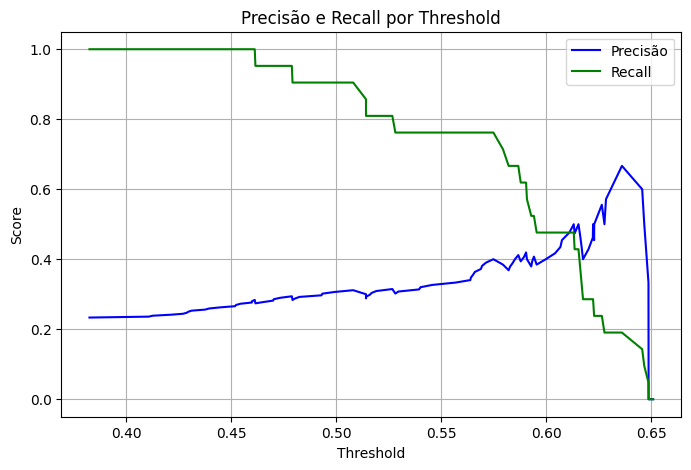

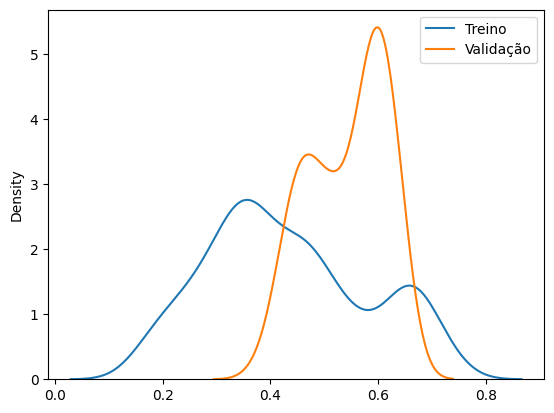

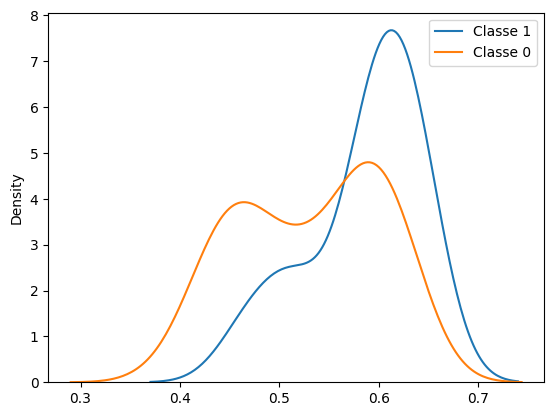

In [14]:
recall_minimo = 0.2  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(modelo, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [15]:
from sklearn.calibration import CalibratedClassifierCV


calibrated_model = CalibratedClassifierCV(modelo, method='isotonic', cv=5)
calibrated_model.fit(X_train.values, y_train.values)

CalibratedClassifierCV(cv=5,
                       estimator=RandomForestClassifier(class_weight='balanced',
                                                        max_depth=3,
                                                        min_samples_leaf=50,
                                                        n_estimators=200,
                                                        n_jobs=-1,
                                                        random_state=42),
                       method='isotonic')

In [16]:
avaliacao_treino_janelas = tr.avaliar_modelo_janelas_deslizantes_thresholds(calibrated_model, X_train.values, y_train.values, recall_minimo=0.05, window_size=30) 
avaliacao_treino_janelas


Threshold 0.50 - AUC: 0.870
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000
Nenhum threshold atendeu ao recall mínimo de 0.05. Seguindo com 0.5


{'precisao_media': 0, 'recall_media': 0, 'threshold_ideal': 0.5}

In [17]:
pd.Series(calibrated_model.predict_proba(X_train.values)[:, 1]).describe()

count    505.000000
mean       0.180415
std        0.085552
min        0.066957
25%        0.130838
50%        0.130838
75%        0.257624
max        0.359846
dtype: float64

Avaliar e logar modelo
MLflow Run ID: 73e49856a9be4b4ab205c9124dcf9199 para PRIO3.SA_15dias_x_0.05val_5dias_alvo
AUC no treino: 0.864
AUC na validação: 0.710

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.870
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000
Nenhum threshold atendeu ao recall mínimo de 0.05. Seguindo com 0.5

Threshold ideal baseado em recall mínimo: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 21.0
Sinais de compra previstos na validação: 0
Modelo PRIO3.SA_15dias_x_0.05val_5dias_alvo salvo na run 73e49856a9be4b4ab205c9124dcf9199


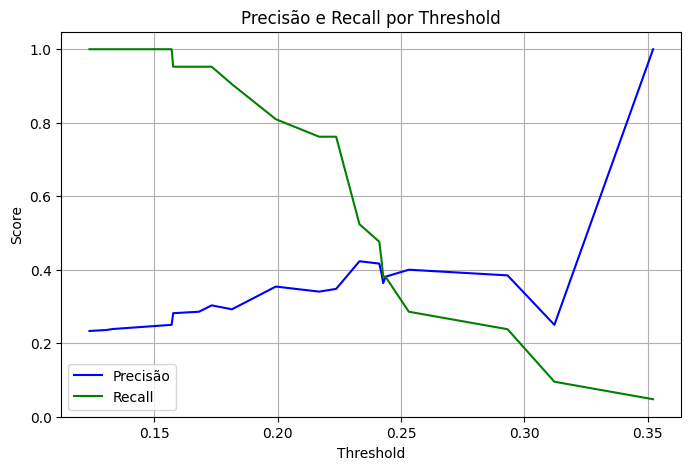

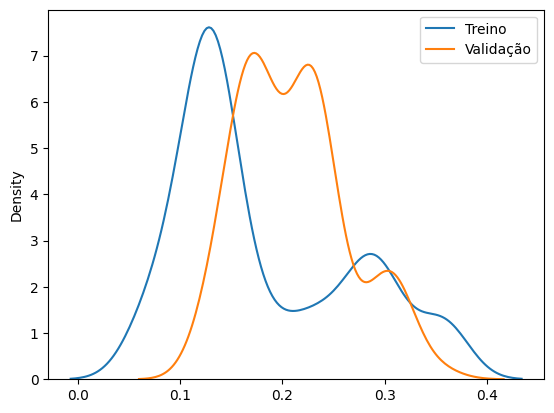

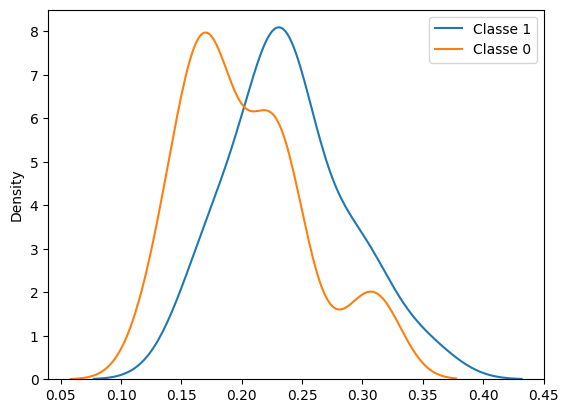

In [18]:
recall_minimo = 0.05  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(calibrated_model, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)


# Redução de features

## Eliminação por correlação

In [18]:
X_filtrado, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
print("Features removidas por alta correlação:", removidas)

Features removidas por alta correlação: ['macd_ultimo', 'macd_conf_ultimo', 'macd_signal_std', 'close_std', 'ibov_amplitude', 'macd_ultimo_norm_atr', 'dias_alta_pct', 'macd_signal_ultimo_norm_atr', 'close_min', 'close_amplitude', 'volume_mean', 'macd_hist_ultimo_norm_atr', 'macd_conf_mean', 'close_mean', 'tr_pct_mean', 'close_ult_vs_mm_janela', 'close_amplitude_norm_atr', 'retorno_mean', 'tr_ultimo_norm_atr', 'rsi_mean', 'macd_mean']


In [19]:
# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)


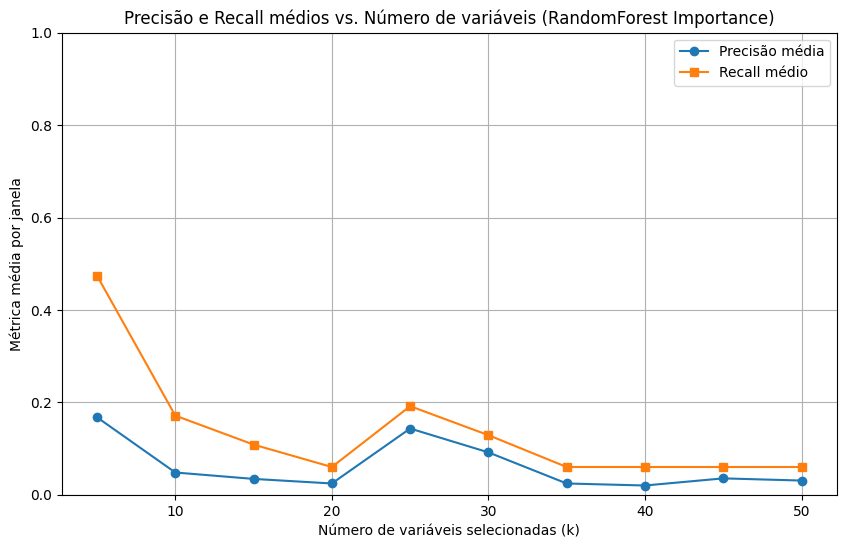

In [20]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas

In [22]:
n_features = 45
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['rsi_std',
 'ipca_ultimo',
 'rsi_volatilidade',
 'close_min',
 'retorno_medio_neg',
 'volume_std',
 'macd_signal_ultimo',
 'dolar_trend',
 'close_mean',
 'volume_mean',
 'close_dist_min',
 'macd_signal_mean',
 'dolar_std',
 'ibov_trend',
 'macd_hist_std',
 'macd_hist_abs_mean',
 'ibov_amplitude',
 'macd_conf_mean',
 'retorno_std',
 'retorno_medio_pos',
 'rsi_mean',
 'macd_hist_abs_ultimo',
 'macd_conf_ultimo',
 'ibov_std',
 'macd_mean',
 'macd_ultimo',
 'close_trend',
 'close_std',
 'retorno_mean',
 'volume_trend',
 'macd_signal_std',
 'dolar_ultimo',
 'close_max',
 'close_ult_vs_mm',
 'dias_alta_pct',
 'close_amplitude',
 'retorno_acumulado',
 'macd_hist_mean',
 'selic_ultimo',
 'macd_std',
 'dias_queda_pct',
 'macd_hist_ultimo',
 'rsi_ultimo',
 'retorno_desde_mudanca_close',
 'retorno_desde_mudanca_dolar']

In [23]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [30]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=5,
                                        #min_samples_split=50,
                                        min_samples_leaf=20,                                        
                                        max_features=0.2,
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.935
AUC na validação: 0.678
Diferença AUC (Treino - Validação): 0.257
PROVÁVEL OVERFITTING


Avaliar e logar modelo
MLflow Run ID: 005176776fb94b97be533e8e09eca682 para VALE3.SA_60dias_x_0.03val_8dias_alvo
AUC no treino: 0.935
AUC na validação: 0.678

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.52
  Precisão Média Esperada: 96.34%
  Recall Médio Esperado: 34.37%
  Janelas Usadas para Precisão: 235.0

Threshold ideal baseado em recall mínimo: 0.52

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 44.0
Sinais de compra previstos na validação: 0
Modelo VALE3.SA_60dias_x_0.03val_8dias_alvo salvo na run 005176776fb94b97be533e8e09eca682


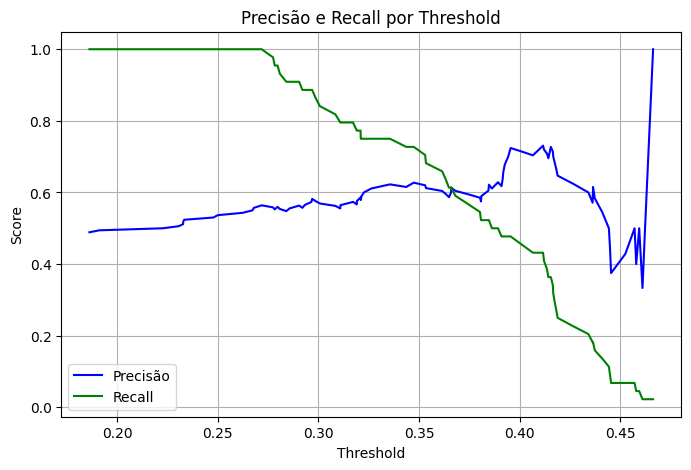

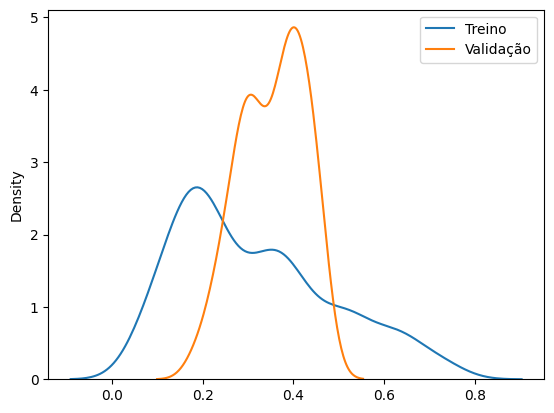

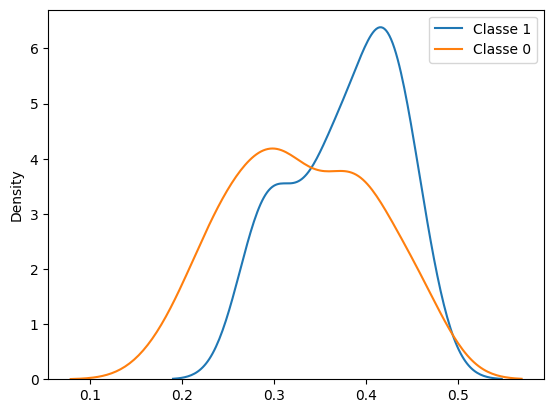

In [32]:
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=0.3)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

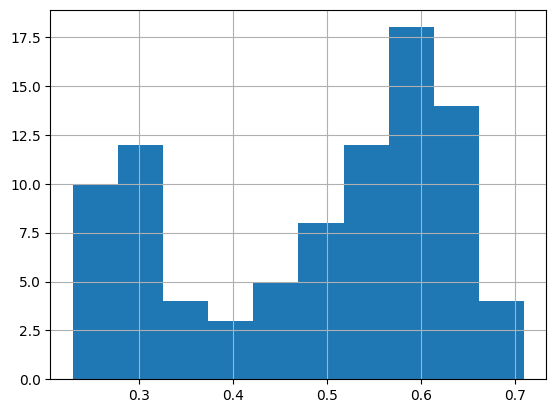

In [24]:
pd.Series(probas).hist()